# 프로젝트 : 네이버 영화리뷰 감성분석 도전하기

이전 스텝까지는 영문 텍스트의 감정 분석을 진행해 보았습니다. 그렇다면 이번에는 한국어 텍스트의 감정 분석을 진행해 보면 어떨까요? 오늘 활용할 데이터셋은 네이버 영화의 댓글을 모아 구성된 [Naver sentiment movie corpus](https://github.com/e9t/nsmc)입니다.

아래와 같이 다운로드를 진행해 주세요.



```
$ wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
$ wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt
$ mv ratings_*.txt ~/aiffel/sentiment_classification/data
$ pip install konlpy
$ sudo apt-get install git
$ sudo apt-get install curl
$ bash <(curl -s https://raw.githubusercontent.com/konlpy/konlpy/master/scripts/mecab.sh)

```

프로젝트 진행 순서는 다음과 같습니다.



In [ ]:
!wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
!wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt
!mv ratings_*.txt /content/data
!pip install konlpy
!sudo apt-get install git
!sudo apt-get install curl
# !bash <(curl -s https://raw.githubusercontent.com/konlpy/konlpy/master/scripts/mecab.sh)

--2026-11-14 21:08:18--  https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 

200 OK
Length: 14628807 (14M) [text/plain]
Saving to: ‘ratings_train.txt’

ratings_train.txt   100%[===================>]  13.95M  --.-KB/s    in 0.1s    

2026-11-14 21:08:19 (138 MB/s) - ‘ratings_train.txt’ saved [14628807/14628807]



--2026-11-14 21:08:19--  https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 

200 OK
Length: 4893335 (4.7M) [application/octet-stream]
Saving to: ‘ratings_test.txt’

ratings_test.txt    100%[===================>]   4.67M  --.-KB/s    in 0.07s   

2026-11-14 21:08:19 (62.8 MB/s) - ‘ratings_test.txt’ saved [4893335/4893335]



mv: target '/content/data': No such file or directory


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/19.4 MB ? eta -:--:--

... (5 outputs left out)

0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


Reading package lists... Done


Building dependency tree... Done
Reading state information... Done
curl is already the newest version (8.5.0-2ubuntu10.16).


0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/27.8 MB ? eta -:--:--

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 84.0 MB/s  0:00:00


## 라이브러리 버전을 확인해 봅니다
---
사용할 라이브러리 버전을 둘러봅시다.

In [ ]:
import pandas
import konlpy
import gensim

print(pandas.__version__)
print(konlpy.__version__)
print(gensim.__version__)

2.2.3
0.6.0
4.4.0


## 1) 데이터 준비와 확인
---

In [ ]:
import pandas as pd

# 데이터를 읽어봅시다.
train_data = pd.read_table('/content/ratings_train.txt')
test_data = pd.read_table('/content/ratings_test.txt')

train_data.head()

,id,document,label
0,9976970,아 더빙.. 진짜 짜증나네요 목소리,0
1,3819312,흠...포스터보고 초딩영화줄....오버연기조차 가볍지 않구나,1
2,10265843,너무재밓었다그래서보는것을추천한다,0
3,9045019,교도소 이야기구먼 ..솔직히 재미는 없다..평점 조정,0
4,6483659,사이몬페그의 익살스런 연기가 돋보였던 영화!스파이더맨에서 늙어보이기만 했던 커스틴 ...,1


## 2) 데이터로더 구성
---
실습 때 다루었던 IMDB 데이터셋은 텍스트를 가공하여 `imdb.data_loader()` 메서드를 호출하면 숫자 인덱스로 변환된 텍스트와 `word_to_index` 딕셔너리까지 친절하게 제공합니다. 그러나 이번에 다루게 될 nsmc 데이터셋은 전혀 가공되지 않은 텍스트 파일로 이루어져 있습니다. 이것을 읽어서 `imdb.data_loader()`와 동일하게 동작하는 자신만의 `data_loader`를 만들어 보는 것으로 시작합니다. `data_loader` 안에서는 다음을 수행해야 합니다.

- 데이터의 중복 제거
- NaN 결측치 제거
- 한국어 토크나이저로 토큰화
- 불용어(Stopwords) 제거
- 사전`word_to_index` 구성
- 텍스트 스트링을 사전 인덱스 스트링으로 변환
- `X_train`, `y_train`, `X_test`, `y_test`, `word_to_index` 리턴

In [ ]:
## 코랩 Mecab() 설치를 위한 추가 코드_1

!pip install Korpora

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [Korpora]


In [ ]:
## 코랩 Mecab() 설치를 위한 추가 코드_2

!git clone https://github.com/SOMJANG/Mecab-ko-for-Google-Colab.git

Cloning into 'Mecab-ko-for-Google-Colab'...


remote: Enumerating objects: 138, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 138 (delta 26), reused 22 (delta 8), pack-reused 91 (from 1)
Receiving objects: 100% (138/138), 1.72 MiB | 20.19 MiB/s, done.
Resolving deltas: 100% (65/65), done.


In [ ]:
## 코랩 Mecab() 설치를 위한 추가 코드_3

%cd Mecab-ko-for-Google-Colab/

/content/Mecab-ko-for-Google-Colab


In [ ]:
## 코랩 Mecab() 설치를 위한 추가 코드_4

!bash install_mecab-ko_on_colab_light_220429.sh

Installing konlpy.....
Done
Installing mecab-0.996-ko-0.9.2.tar.gz.....
from https://bitbucket.org/eunjeon/mecab-ko/downloads/mecab-0.996-ko-0.9.2.tar.gz
--2026-10-14 06:10:43--  https://bitbucket.org/eunjeon/mecab-ko/downloads/mecab-0.996-ko-0.9.2.tar.gz
Resolving bitbucket.org (bitbucket.org)... 13.200.41.134, 13.200.41.135, 13.200.41.136, ...
Connecting to bitbucket.org (bitbucket.org)|13.200.41.134|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-10-14 06:10:43 ERROR 404: Not Found.

Done
Unpacking mecab-0.996-ko-0.9.2.tar.gz.......
Done
Change Directory to mecab-0.996-ko-0.9.2.......
install_mecab-ko_on_colab_light_220429.sh: line 23: cd: mecab-0.996-ko-0.9.2/: No such file or directory
installing mecab-0.996-ko-0.9.2.tar.gz........
configure
make
make check
make install
ldconfig
Done
Change Directory to /content
from https://bitbucket.org/eunjeon/mecab-ko-dic/downloads/mecab-ko-dic-2.1.1-20180720.tar.gz
--2026-10-14 06:10:46--  https://bitbucket.org/e

In [ ]:
%pip install -q python-mecab-ko

  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


In [ ]:
from mecab import MeCab
import numpy as np
from collections import Counter

tokenizer = MeCab()
stopwords = ['의','가','이','은','들','는','좀','잘','걍','과','도','를','으로','자','에','와','한','하다']

def load_data(train_data, test_data, num_words=10000):
    train_data.drop_duplicates(subset=['document'], inplace=True)
    train_data = train_data.dropna(how = 'any')
    test_data.drop_duplicates(subset=['document'], inplace=True)
    test_data = test_data.dropna(how = 'any')

    X_train = []
    for sentence in train_data['document']:
        temp_X = tokenizer.morphs(sentence) # 토큰화
        temp_X = [word for word in temp_X if not word in stopwords] # 불용어 제거
        X_train.append(temp_X)

    X_test = []
    for sentence in test_data['document']:
        temp_X = tokenizer.morphs(sentence) # 토큰화
        temp_X = [word for word in temp_X if not word in stopwords] # 불용어 제거
        X_test.append(temp_X)

    words = np.concatenate(X_train).tolist()
    counter = Counter(words)
    counter = counter.most_common(10000-4)
    vocab = ['', '', '', ''] + [key for key, _ in counter]
    word_to_index = {word:index for index, word in enumerate(vocab)}

    def wordlist_to_indexlist(wordlist):
        return [word_to_index[word] if word in word_to_index else word_to_index[''] for word in wordlist]

    X_train = list(map(wordlist_to_indexlist, X_train))
    X_test = list(map(wordlist_to_indexlist, X_test))

    return X_train, np.array(list(train_data['label'])), X_test, np.array(list(test_data['label'])), word_to_index

X_train, y_train, X_test, y_test, word_to_index = load_data(train_data, test_data)

In [ ]:
index_to_word = {index:word for word, index in word_to_index.items()}

In [ ]:
# 문장 1개를 활용할 딕셔너리와 함께 주면, 단어 인덱스 리스트 벡터로 변환해 주는 함수입니다.
# 단, 모든 문장은 <BOS>로 시작하는 것으로 합니다.
def get_encoded_sentence(sentence, word_to_index):
    return [word_to_index['<BOS>']]+[word_to_index[word] if word in word_to_index else word_to_index['<UNK>'] for word in sentence.split()]

# 여러 개의 문장 리스트를 한꺼번에 단어 인덱스 리스트 벡터로 encode해 주는 함수입니다.
def get_encoded_sentences(sentences, word_to_index):
    return [get_encoded_sentence(sentence, word_to_index) for sentence in sentences]

# 숫자 벡터로 encode된 문장을 원래대로 decode하는 함수입니다.
def get_decoded_sentence(encoded_sentence, index_to_word):
    return ' '.join(index_to_word[index] if index in index_to_word else '<UNK>' for index in encoded_sentence[1:])  #[1:]를 통해 <BOS>를 제외

# 여러 개의 숫자 벡터로 encode된 문장을 한꺼번에 원래대로 decode하는 함수입니다.
def get_decoded_sentences(encoded_sentences, index_to_word):
    return [get_decoded_sentence(encoded_sentence, index_to_word) for encoded_sentence in encoded_sentences]

## 3) 모델 구성을 위한 데이터 분석 및 가공
---
- 데이터셋 내 문장 길이 분포
- 적절한 최대 문장 길이 지정
- keras.preprocessing.sequence.pad_sequences 을 활용한 패딩 추가

### 3-1. 문장 길이 통계와 최대 길이(maxlen)

In [ ]:
total_data_text = list(X_train) + list(X_test)
num_tokens = [len(tokens) for tokens in total_data_text]
num_tokens = np.array(num_tokens)
print('문장길이 평균 : ', np.mean(num_tokens))
print('문장길이 최대 : ', np.max(num_tokens))
print('문장길이 표준편차 : ', np.std(num_tokens))

max_tokens = np.mean(num_tokens) + 2 * np.std(num_tokens)
maxlen = int(max_tokens)
print('pad_sequences maxlen : ', maxlen)
print(f'전체 문장의 {np.sum(num_tokens < max_tokens) / len(num_tokens)}%가 maxlen 설정값 이내에 포함됩니다. ')

문장길이 평균 :  15.969355837799927
문장길이 최대 :  116
문장길이 표준편차 :  12.843536204665021
pad_sequences maxlen :  41
전체 문장의 0.9342988343341575%가 maxlen 설정값 이내에 포함됩니다. 


### 3-2. 패딩과 텐서 변환

In [ ]:
import torch

def pad_sequences(data, maxlen):
    padded_data = []
    for sentence in data:
        if len(sentence) < maxlen:
            sentence = [0] * (maxlen - len(sentence)) + sentence
        else:
            sentence = sentence[:maxlen]
        padded_data.append(sentence)
    return np.array(padded_data)

x_train_padded = pad_sequences(X_train, maxlen)
x_test_padded = pad_sequences(X_test, maxlen)

x_train_tensor = torch.tensor(x_train_padded, dtype=torch.long)
x_test_tensor = torch.tensor(x_test_padded, dtype=torch.long)

print(x_train_tensor.shape)

torch.Size([146182, 41])


## 4) 모델 구성 및 validation set 구성
---
모델은 3가지 이상 다양하게 구성하여 실험해 보세요.

### 4-1. 모델 3가지 정의

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class LSTM(nn.Module):
    def __init__(self, vocab_size, word_vector_dim):
        super(LSTM, self).__init__()
        self.embedding = nn.Embedding(vocab_size, word_vector_dim)
        self.lstm = nn.LSTM(word_vector_dim, 8, batch_first=True)
        self.fc1 = nn.Linear(8, 8)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(8, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.embedding(x)
        lstm_out, (h_n, c_n) = self.lstm(x)
        x = h_n[-1]
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.sigmoid(x)
        return x

class CNN1D(nn.Module):
    def __init__(self, vocab_size, word_vector_dim):
        super(CNN1D, self).__init__()
        self.embedding = nn.Embedding(vocab_size, word_vector_dim)
        self.conv1 = nn.Conv1d(word_vector_dim, 16, kernel_size=7)
        self.conv2 = nn.Conv1d(16, 16, kernel_size=7)
        self.pool = nn.MaxPool1d(5)
        self.global_max_pooling = nn.AdaptiveMaxPool1d(1)
        self.fc1 = nn.Linear(16, 8)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(8, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.embedding(x)
        x = x.permute(0, 2, 1)
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.conv2(x)
        x = self.relu(x)
        x = self.global_max_pooling(x)
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.sigmoid(x)
        return x

class GlobalMaxPooling(nn.Module):
    def __init__(self, vocab_size, word_vector_dim):
        super(GlobalMaxPooling, self).__init__()
        self.embedding = nn.Embedding(vocab_size, word_vector_dim)
        self.global_max_pooling = nn.AdaptiveMaxPool1d(1)
        self.fc1 = nn.Linear(word_vector_dim, 8)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(8, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.embedding(x)
        x = x.permute(0, 2, 1)
        x = self.global_max_pooling(x)
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.sigmoid(x)
        return x

### 4-2. 모델 만들기

In [ ]:
vocab_size = 10000
word_vector_dim = 16

lstm = LSTM(vocab_size, word_vector_dim)
cnn = CNN1D(vocab_size, word_vector_dim)
global_max_pooling = GlobalMaxPooling(vocab_size, word_vector_dim)

print(lstm)
print(cnn)
print(global_max_pooling)

LSTM(
  (embedding): Embedding(10000, 16)
  (lstm): LSTM(16, 8, batch_first=True)
  (fc1): Linear(in_features=8, out_features=8, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=8, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
CNN1D(
  (embedding): Embedding(10000, 16)
  (conv1): Conv1d(16, 16, kernel_size=(7,), stride=(1,))
  (conv2): Conv1d(16, 16, kernel_size=(7,), stride=(1,))
  (pool): MaxPool1d(kernel_size=5, stride=5, padding=0, dilation=1, ceil_mode=False)
  (global_max_pooling): AdaptiveMaxPool1d(output_size=1)
  (fc1): Linear(in_features=16, out_features=8, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=8, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
GlobalMaxPooling(
  (embedding): Embedding(10000, 16)
  (global_max_pooling): AdaptiveMaxPool1d(output_size=1)
  (fc1): Linear(in_features=16, out_features=8, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=8, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


### 4-3. validation set 분리

In [ ]:
x_val = x_train_tensor[:10000]
y_val = y_train[:10000]

partial_x_train = x_train_tensor[10000:]
partial_y_train = y_train[10000:]

print(partial_x_train.shape)
print(partial_y_train.shape)

torch.Size([136182, 41])
(136182,)


## 5) 모델 훈련 개시
---

### 5-1. 결과 기록 리스트와 DataLoader 준비

In [ ]:
names = []
test_accs = []
val_acc_list = []

In [ ]:
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

partial_x_train_tensor = torch.tensor(partial_x_train, dtype=torch.long)
partial_y_train_tensor = torch.tensor(partial_y_train, dtype=torch.float)

x_val_tensor = torch.tensor(x_val, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.float)

train_dataset = TensorDataset(partial_x_train_tensor, partial_y_train_tensor)
val_dataset = TensorDataset(x_val_tensor, y_val_tensor)

train_loader = DataLoader(train_dataset, batch_size=512, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)

y_test_tensor = torch.tensor(y_test, dtype=torch.float)
test_dataset = TensorDataset(x_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=512, shuffle=False)

/tmp/ipykernel_1418/1777624543.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  partial_x_train_tensor = torch.tensor(partial_x_train, dtype=torch.long)
/tmp/ipykernel_1418/1777624543.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x_val_tensor = torch.tensor(x_val, dtype=torch.long)


### 5-2. 학습·평가·그래프를 묶은 ModelTrainer 클래스

In [ ]:
class ModelTrainer:
    def __init__(self, model):
        self.optimizer = optim.Adam(model.parameters())
        self.loss_fn = torch.nn.BCELoss()
        self.model = model
        self.name = type(model).__name__
        self.train_losses = []
        self.val_losses = []
        self.train_accs = []
        self.val_accs = []
    def train(self, epochs = 1):
        for epoch in range(epochs):
            self.model.train()
            running_loss = 0.0
            correct = 0
            total = 0

            for inputs, labels in train_loader:
                self.optimizer.zero_grad()

                outputs = self.model(inputs)
                loss = self.loss_fn(outputs.squeeze(), labels)
                loss.backward()
                self.optimizer.step()

                running_loss += loss.item()

                predicted = (outputs.squeeze() > 0.5).float()
                correct += (predicted == labels).sum().item()
                total += labels.size(0)

            self.train_losses.append(running_loss / len(train_loader))
            self.train_accs.append(correct / total)

            self.model.eval()
            val_loss = 0.0
            val_correct = 0
            val_total = 0

            with torch.no_grad():
                for inputs, labels in val_loader:
                    outputs = self.model(inputs)
                    loss = self.loss_fn(outputs.squeeze(), labels)

                    val_loss += loss.item()
                    predicted = (outputs.squeeze() > 0.5).float()
                    val_correct += (predicted == labels).sum().item()
                    val_total += labels.size(0)

            self.val_losses.append(val_loss / len(val_loader))
            self.val_accs.append(val_correct / val_total)

            print(f"Epoch {epoch+1}/{epochs} - "
                f"Train Loss: {self.train_losses[-1]:.4f}, Train Accuracy: {self.train_accs[-1]:.4f} - "
                f"Validation Loss: {self.val_losses[-1]:.4f}, Validation Accuracy: {self.val_accs[-1]:.4f}")
    def test(self):
        self.model.eval()
        test_loss = 0.0
        test_correct = 0
        test_total = 0

        with torch.no_grad():
            for inputs, labels in test_loader:
                outputs = self.model(inputs)
                loss = self.loss_fn(outputs.squeeze(), labels)

                test_loss += loss.item()
                predicted = (outputs.squeeze() > 0.5).float()
                test_correct += (predicted == labels).sum().item()
                test_total += labels.size(0)

        print(f"Test Loss: {test_loss / len(test_loader):.4f}, Test Accuracy: {test_correct / test_total:.4f}")

        names.append(self.name)

        test_accs.append(test_correct / test_total)
        val_acc_list.append(self.val_accs)
    def loss_graph(self, epochs):
        epochs_range = range(1, epochs + 1)

        plt.plot(epochs_range, self.train_losses, 'bo', label='Training loss')
        plt.plot(epochs_range, self.val_losses, 'b', label='Validation loss')
        plt.title(self.name + ' - Training and Validation Loss')
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.legend()
        plt.show()
    def acc_graph(self, epochs):
        epochs_range = range(1, epochs + 1)

        plt.clf()

        plt.plot(epochs_range, self.train_accs, 'bo', label='Training accuracy')
        plt.plot(epochs_range, self.val_accs, 'b', label='Validation accuracy')
        plt.title(self.name + ' - Training and Validation Accuracy')
        plt.xlabel('Epochs')
        plt.ylabel('Accuracy')
        plt.legend()
        plt.show()

### 5-3. 세 모델 학습

In [ ]:
trainers = [ModelTrainer(lstm), ModelTrainer(cnn), ModelTrainer(global_max_pooling)]
epochs = 5
for trainer in trainers:
    print("모델 학습 : " + trainer.name)
    trainer.train(epochs)

모델 학습 : LSTM


Epoch 1/5 - Train Loss: 0.6576, Train Accuracy: 0.5886 - Validation Loss: 0.5510, Validation Accuracy: 0.7294


Epoch 2/5 - Train Loss: 0.4977, Train Accuracy: 0.7643 - Validation Loss: 0.4572, Validation Accuracy: 0.7854


Epoch 3/5 - Train Loss: 0.4309, Train Accuracy: 0.8047 - Validation Loss: 0.4188, Validation Accuracy: 0.8101


Epoch 4/5 - Train Loss: 0.3954, Train Accuracy: 0.8252 - Validation Loss: 0.3981, Validation Accuracy: 0.8205


Epoch 5/5 - Train Loss: 0.3720, Train Accuracy: 0.8381 - Validation Loss: 0.3822, Validation Accuracy: 0.8280
모델 학습 : CNN1D


... (6 outputs left out)

Epoch 2/5 - Train Loss: 0.6273, Train Accuracy: 0.6477 - Validation Loss: 0.5924, Validation Accuracy: 0.6817


Epoch 3/5 - Train Loss: 0.5545, Train Accuracy: 0.7147 - Validation Loss: 0.5303, Validation Accuracy: 0.7329


Epoch 4/5 - Train Loss: 0.5056, Train Accuracy: 0.7498 - Validation Loss: 0.4946, Validation Accuracy: 0.7584


Epoch 5/5 - Train Loss: 0.4746, Train Accuracy: 0.7714 - Validation Loss: 0.4719, Validation Accuracy: 0.7705


### 5-4. test 평가

In [ ]:
for trainer in trainers:
    print("모델 평가 : " + trainer.name)
    trainer.test()

모델 평가 : LSTM


Test Loss: 0.3906, Test Accuracy: 0.8259
모델 평가 : CNN1D


Test Loss: 0.3935, Test Accuracy: 0.8215
모델 평가 : GlobalMaxPooling


Test Loss: 0.4782, Test Accuracy: 0.7701


## 6) Loss, Accuracy 그래프 시각화
---

### 6-1. Loss 그래프

모델 loss 그래프 : LSTM


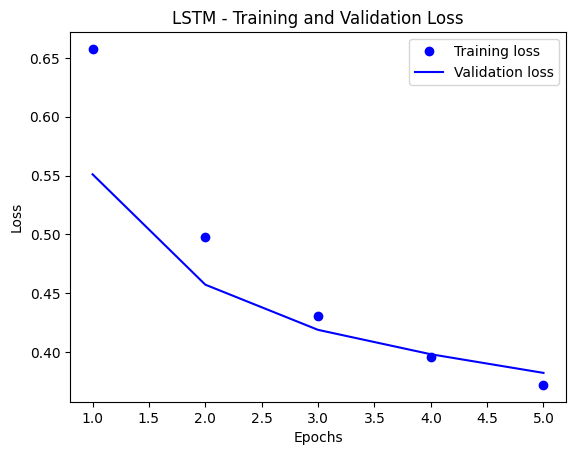

모델 loss 그래프 : CNN1D


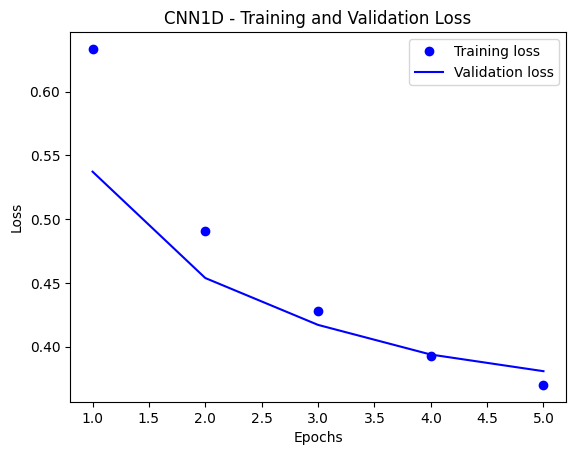

모델 loss 그래프 : GlobalMaxPooling


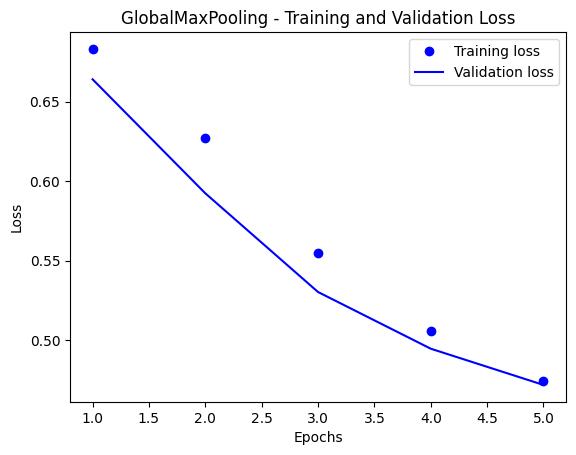

In [ ]:
for trainer in trainers:
    print("모델 loss 그래프 : " + trainer.name)
    trainer.loss_graph(epochs)

### 6-2. Accuracy 그래프

모델 acc 그래프 : LSTM


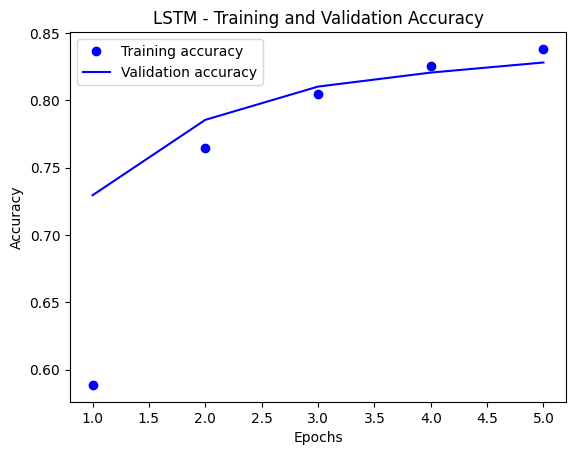

모델 acc 그래프 : CNN1D


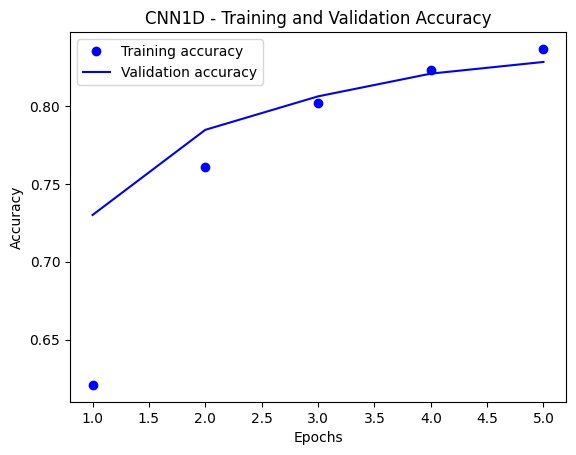

모델 acc 그래프 : GlobalMaxPooling


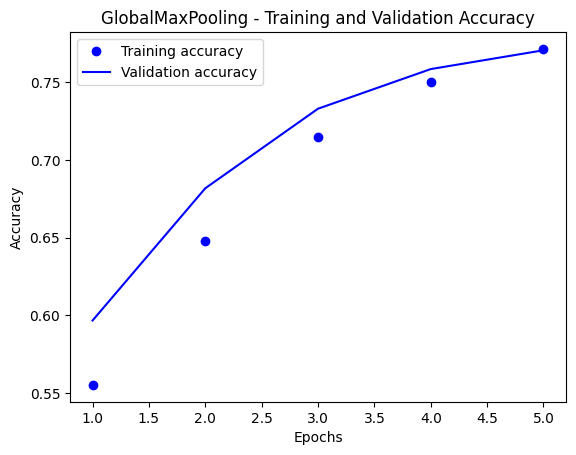

In [ ]:
for trainer in trainers:
    print("모델 acc 그래프 : " + trainer.name)
    trainer.acc_graph(epochs)

### 6-3. 모델별 test 정확도와 validation 정확도 비교

                 모델  test acc
0              LSTM    0.8259
1             CNN1D    0.8215
2  GlobalMaxPooling    0.7701


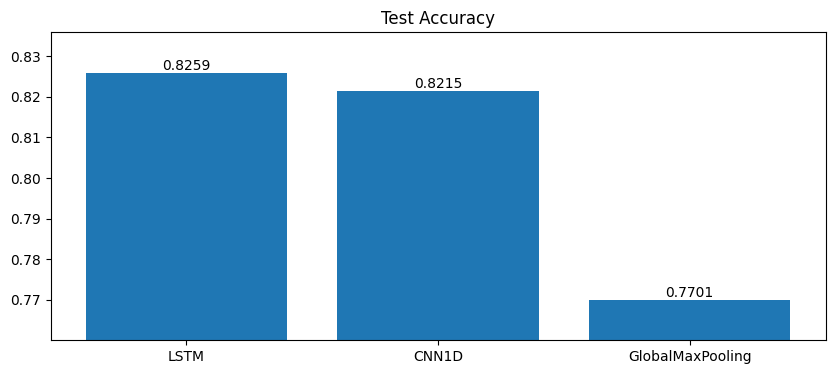

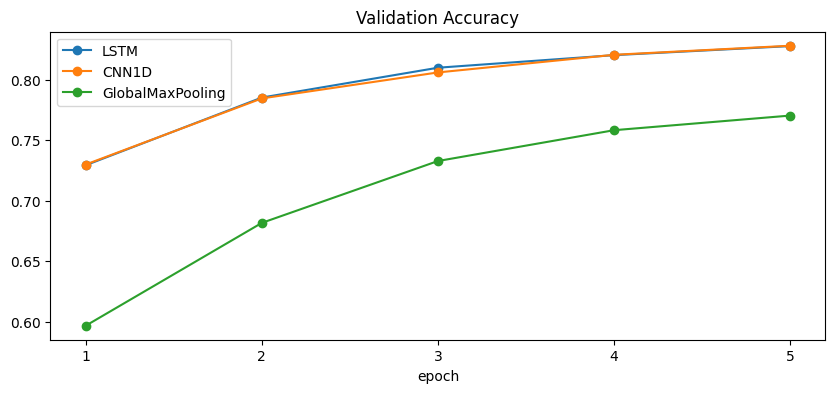

In [ ]:
result_df = pd.DataFrame({'모델': names,
                          'test acc': test_accs})
print(result_df.round(4))

plt.figure(figsize=(10, 4))
plt.bar(names, test_accs)
for i in range(len(names)):
    plt.text(i, test_accs[i], round(test_accs[i], 4), ha='center', va='bottom')
plt.ylim(min(test_accs) - 0.01, max(test_accs) + 0.01)
plt.title("Test Accuracy")
plt.show()

plt.figure(figsize=(10, 4))
for i in range(len(names)):
    plt.plot(range(1, len(val_acc_list[i]) + 1), val_acc_list[i], marker='o', label=names[i])
plt.xticks(range(1, epochs + 1))
plt.xlabel("epoch")
plt.title("Validation Accuracy")
plt.legend()
plt.show()

## 7) 학습된 Embedding 레이어 분석
---

### 7-1. 준비: 저장 폴더, gensim, 확인할 단어

In [ ]:
!mkdir -p /content/sentiment_classification/data

from gensim.models.keyedvectors import Word2VecKeyedVectors

words = ['끝', '재미', '감동']

### 7-2. 임베딩 분석 클래스 EmbeddingAnalyzer

In [ ]:
class EmbeddingAnalyzer:
    def __init__(self, model):
        self.name = type(model).__name__
        embedding_layer = model.embedding
        self.weights = embedding_layer.weight.detach().cpu().numpy()
        self.word2vec_file_path = '/content/sentiment_classification/data/word2vec_' + self.name + '.txt'
    def save(self):
        with open(self.word2vec_file_path, 'w') as f:
            f.write('{} {}\n'.format(vocab_size - 4, self.weights.shape[1]))

            for i in range(4, vocab_size):
                f.write('{} {}\n'.format(index_to_word[i], ' '.join(map(str, self.weights[i, :]))))
    def load(self):
        self.word_vectors = Word2VecKeyedVectors.load_word2vec_format(self.word2vec_file_path, binary=False)
    def similar(self, words, topn = 5):
        print("임베딩 모델 : " + self.name, self.weights.shape)
        for word in words:
            print(word, ":", [similar_word for similar_word, _ in self.word_vectors.similar_by_word(word, topn=topn)])

### 7-3. 세 모델의 임베딩에서 비슷한 단어 찾기

In [ ]:
analyzers = [EmbeddingAnalyzer(trainer.model) for trainer in trainers]

for analyzer in analyzers:
    analyzer.save()
    analyzer.load()
    analyzer.similar(words)

임베딩 모델 : LSTM (10000, 16)
끝 : ['왜', '공포감', '찾', '지식', '남긴다']
재미 : ['양아치', '유태인', '테론', '어선', 'MBC']
감동 : ['오즈', '아름다워요', '키는', '아낌없', '조타']


임베딩 모델 : CNN1D (10000, 16)
끝 : ['상속자', '설경구', '년', '송새벽', '강지환']
재미 : ['앗', '갖', '박한별', '어우', '할려고']
감동 : ['바리', '홍련', '해답', '국산', '화이팅']


임베딩 모델 : GlobalMaxPooling (10000, 16)
끝 : ['아씨', '였으며', '전직', '귀여니', '유료']
재미 : ['비장', '김지운', '주류', '보삼', '부대']
감동 : ['어마어마', '집중', '엽', '정복', '비오']


## 8) 한국어 Word2Vec 임베딩 활용하여 성능 개선
---
- 한국어 Word2Vec은 /data 폴더 안에 있는 word2vec_ko.model을 활용하세요.
- 한국어 Word2Vec을 활용할 때는 `load_word2vec_format()` 형태가 아닌 `load()` 형태로 모델을 불러와주세요. 또한 모델을 활용할 때에는 아래 예시와 같이 `.wv`를 붙여서 활용합니다. 좀더 자세한 활용법에 대해선 다음 링크들을 참조해주세요. [참고 링크1](https://radimrehurek.com/gensim/auto_examples/tutorials/run_word2vec.html#storing-and-loading-models), [참고 링크2](https://radimrehurek.com/gensim/models/keyedvectors.html)



```
# 예시 코드
from gensim.models.keyedvectors import Word2VecKeyedVectors
word_vectors = Word2VecKeyedVectors.load(word2vec_file_path)
vector = word_vectors.wv[‘끝’]
```



### 8-1. 한국어 Word2Vec 불러오기

수업 자료에 `word2vec_ko.model`이 없어서, 공개된 한국어 Word2Vec([Kyubyong/wordvectors](https://github.com/Kyubyong/wordvectors)의 `ko.bin`, 200차원)을 받아 최신 gensim(4.x)에서 열리는 형식으로 다시 저장한 파일을 `/content`에 올려 사용했습니다.

In [ ]:
from gensim.models.keyedvectors import Word2VecKeyedVectors

word2vec_path = '/content/word2vec_ko.model'
word2vec = Word2VecKeyedVectors.load(word2vec_path)
vector = word2vec.wv['끝']

### 8-2. 사전학습 Word2Vec에서 비슷한 단어 찾기

In [ ]:
print("임베딩 모델 : 사전학습 Word2Vec", word2vec.wv.vectors.shape)
for word in words:
    print(word, ":", [similar_word for similar_word, _ in word2vec.wv.similar_by_word(word, topn=5)])

임베딩 모델 : 사전학습 Word2Vec (30185, 200)
끝 : ['겨드랑이', '마지막', '발목', '밑부분', '허벅지']
재미 : ['취미', '유머', '매력', '흥미', '공짜']
감동 : ['감명', '감격', '실망', '감화', '감탄']


### 8-3. 사전의 단어마다 Word2Vec 벡터 복사

In [ ]:
vocab_size = 10000
word_vector_dim = word2vec.wv.vector_size
embedding_matrix = np.random.rand(vocab_size, word_vector_dim)

for i in range(4,vocab_size):
    if index_to_word[i] in word2vec.wv:
        embedding_matrix[i] = word2vec.wv[index_to_word[i]]

### 8-4. Word2Vec 임베딩을 넣은 모델

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class Word2VecCNN1D(nn.Module):
    def __init__(self, vocab_size, word_vector_dim, embedding_matrix, maxlen):
        super(Word2VecCNN1D, self).__init__()
        self.embedding = nn.Embedding(vocab_size, word_vector_dim)
        self.embedding.weight = nn.Parameter(torch.tensor(embedding_matrix, dtype=torch.float32))
        self.embedding.weight.requires_grad = True
        self.conv1 = nn.Conv1d(in_channels=word_vector_dim, out_channels=16, kernel_size=7)
        self.pool = nn.MaxPool1d(kernel_size=5)
        self.conv2 = nn.Conv1d(in_channels=16, out_channels=16, kernel_size=7)
        self.global_max_pool = nn.AdaptiveMaxPool1d(1)
        self.fc1 = nn.Linear(16, 8)
        self.fc2 = nn.Linear(8, 1)

    def forward(self, x):
        x = self.embedding(x)
        x = x.permute(0, 2, 1)
        x = F.relu(self.conv1(x))
        x = self.pool(x)
        x = F.relu(self.conv2(x))
        x = self.global_max_pool(x).squeeze(2)
        x = F.relu(self.fc1(x))
        x = torch.sigmoid(self.fc2(x))
        return x

word2vec_cnn = Word2VecCNN1D(vocab_size, word_vector_dim, embedding_matrix, maxlen)
print(word2vec_cnn)

Word2VecCNN1D(
  (embedding): Embedding(10000, 200)
  (conv1): Conv1d(200, 16, kernel_size=(7,), stride=(1,))
  (pool): MaxPool1d(kernel_size=5, stride=5, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(16, 16, kernel_size=(7,), stride=(1,))
  (global_max_pool): AdaptiveMaxPool1d(output_size=1)
  (fc1): Linear(in_features=16, out_features=8, bias=True)
  (fc2): Linear(in_features=8, out_features=1, bias=True)
)


### 8-5. 학습

In [ ]:
word2vec_trainer = ModelTrainer(word2vec_cnn)

print("모델 학습 : " + word2vec_trainer.name)
word2vec_trainer.train(epochs)

모델 학습 : Word2VecCNN1D


Epoch 1/5 - Train Loss: 0.4984, Train Accuracy: 0.7512 - Validation Loss: 0.3970, Validation Accuracy: 0.8223


Epoch 2/5 - Train Loss: 0.3573, Train Accuracy: 0.8440 - Validation Loss: 0.3486, Validation Accuracy: 0.8441


Epoch 3/5 - Train Loss: 0.3131, Train Accuracy: 0.8674 - Validation Loss: 0.3402, Validation Accuracy: 0.8502


Epoch 4/5 - Train Loss: 0.2855, Train Accuracy: 0.8822 - Validation Loss: 0.3400, Validation Accuracy: 0.8521


Epoch 5/5 - Train Loss: 0.2641, Train Accuracy: 0.8923 - Validation Loss: 0.3463, Validation Accuracy: 0.8515


### 8-6. test 평가와 그래프

모델 평가 : Word2VecCNN1D


Test Loss: 0.3586, Test Accuracy: 0.8507


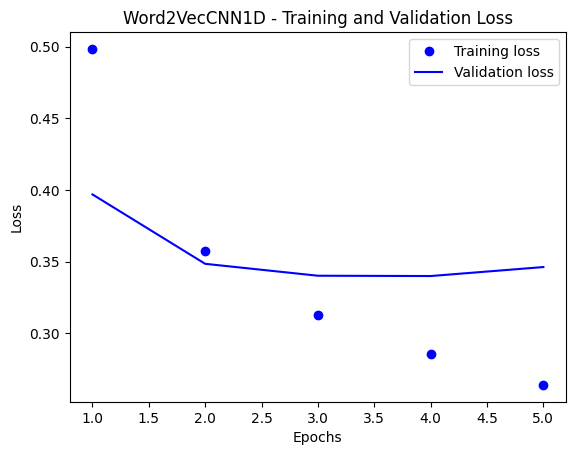

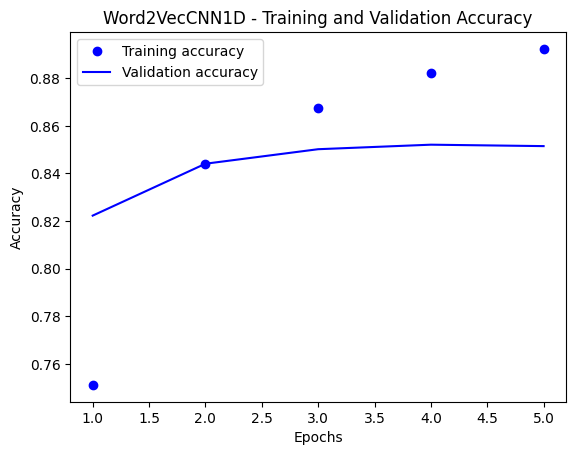

In [ ]:
print("모델 평가 : " + word2vec_trainer.name)
word2vec_trainer.test()

word2vec_trainer.loss_graph(epochs)
word2vec_trainer.acc_graph(epochs)

### 8-7. 네 모델의 test 정확도 비교

In [ ]:
result_df = pd.DataFrame({'모델': names,
                          'test acc': test_accs})
print(result_df.round(4))

                 모델  test acc
0              LSTM    0.8259
1             CNN1D    0.8215
2  GlobalMaxPooling    0.7701
3     Word2VecCNN1D    0.8507
